In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
import numpy as np 
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from pathlib import Path
import os
from src.ekman import Ekman, EkmanConfig, Simulation, StateUpdater, rmse



In [ ]:
TTOT = 24 * 3600 # seconds
UG_TRUE = 10
K_TRUE = 2

In [ ]:
# ====================
# --- TRUTH RUN
# ====================
config = EkmanConfig(  
    spinup_seconds = 60 * 3600,
    output_interval = 60,
    )



model_true = Ekman(ug=UG_TRUE, vg=0, K=K_TRUE, config=config)
model_true.spin_up()

sim_true = Simulation(model_true)

# --- Run Control
truth_run = sim_true.copy()     # Independent branches
ds_true = truth_run.run(until=TTOT) # Control Forecast


In [121]:

def assim_wind_seq(
    ug,
    K,
    vg: float =0,
    h_obs: int = 100,
    sigma_obs: float = 50,
    t0_assim: int = 3600,
    dt_assim: int = 7200,
    n_assim: int = 6,
    run_ctrl: bool = True
):


    print(f"SetUp Ekman with ug:{ug}, vg:{vg}, K:{K}")
    model = Ekman(ug=ug, vg=vg, K=K, config=config)
    model.spin_up()

    sim = Simulation(model)

    # --- Run DA-experiment
    analysis = sim.copy()
    # analysis_ds = analysis.run(until=3600)

    if run_ctrl:
        control = sim.copy()
        ds_ctrl = control.run(until=TTOT)


    # -- Schedule 6 assimilation updates
    for t in range(t0_assim, t0_assim+n_assim*dt_assim, dt_assim):

        # 1. Integrate to assimilation time
        analysis.run(until=t)

        # Get truth value
        utrue = ds_true.sel(time=t, z=H_OBS)["u"]
        vtrue = ds_true.sel(time=t, z=H_OBS)["v"]
        # Extract current background forecast
        idx = np.argmin(abs(analysis.model.z - H_OBS))
        ubg = analysis.model.state.u[idx]
        vbg = analysis.model.state.v[idx]
        # Calculate increments
        du = (utrue - ubg).item()
        dv = (vtrue - vbg).item()

        # Schedule assimilation
        analysis.schedule(t,StateUpdater(du=du, dv=dv, h_obs=h_obs, sigma=sigma_obs))

    # # --- Run simulation
    ds_analysis = analysis.run(until=TTOT)
    # analysis.schedule(1800, StateUpdater(du=1, dv=0.5, h_obs=100, sigma=25))
    # model.integrate(until=TTOT)
    # StateUpdater(du=1, dv=0.5, h_obs=100, sigma=25).update_step(model)


    if run_ctrl:
        return ds_analysis, ds_ctrl
    else:
        return ds_analysis


SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1
SetUp Ekman with ug:8, vg:0, K:1


Text(0.5, 0.98, 'Ekman-Sim with ug: 8 & K: 1   ||   TRUTH ug:10 & K:2')

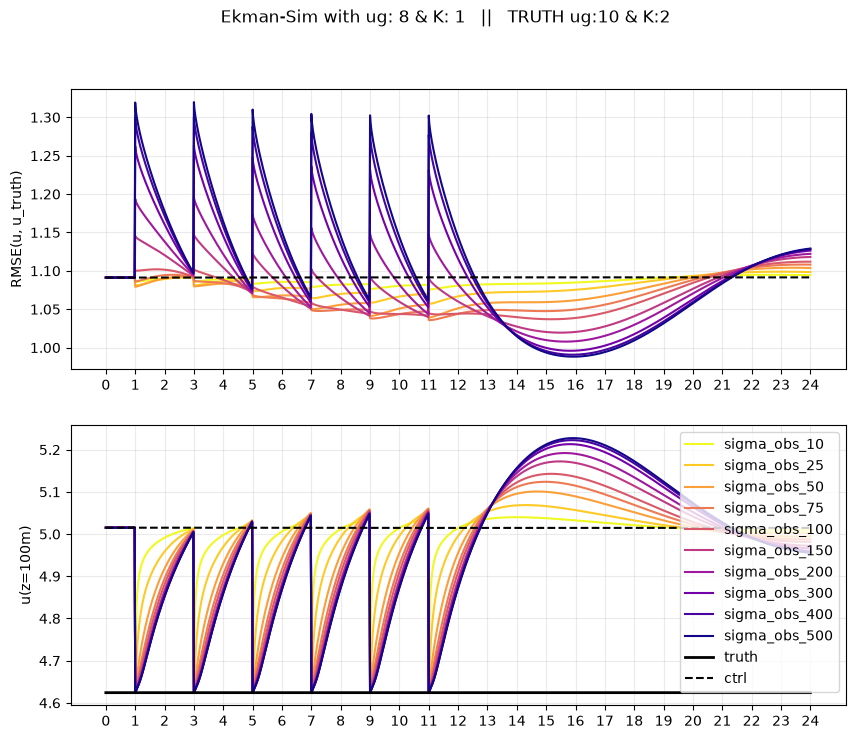

In [130]:
UG_SIM = 8
K_SIM = 1#K_TRUE
H_OBS = 100
SIGMA_OBS = 50


assim_dict = dict()
for idx, loc in enumerate([10,25,50,75,100,150,200,300,400,500]):
    runc = True if idx==0 else False
    
    output = assim_wind_seq(
        UG_SIM, K_SIM, 
        h_obs = H_OBS, 
        sigma_obs = loc,
        run_ctrl = runc
        )
    if runc:
        ds_ctrl = output[1]
    
    assim_dict[f"sigma_obs_{loc}"] = output[0] if runc else output



# ---- PLOTTING
fig, ax = plt.subplots(nrows=2, figsize=(10, 8))

H_PLOT = 100

# Colors from inferno colormap
cmap = plt.get_cmap("plasma_r")
colors = cmap(np.linspace(0, 0.99, len(assim_dict)))
for (label, ds_sim), color in zip(assim_dict.items(), colors):

    z = slice(None, None)
    rmse_da = rmse(ds_sim["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")
    rmse_ctrl = rmse(ds_ctrl["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")

    ds_sim.u.sel(z=H_PLOT).plot(ax=ax[1], color=color, label=label)
    rmse_da.plot(ax=ax[0], color=color, label=label)

rmse_ctrl.plot(ax=ax[0], c="k", linestyle="--", label="ctrl")

ds_true.u.sel(z=H_PLOT).plot(ax=ax[1], label="truth", c="k", linewidth=2)
ds_ctrl.u.sel(z=H_PLOT).plot(ax=ax[1], label="ctrl", c="k", linestyle="--")


ax[0].set_ylabel("RMSE(u, u_truth)")
ax[1].set_ylabel(f"u(z={H_PLOT}m)")

xticks = ds_sim.time.values[::60]
xlabels = [f'{int(x//3600)}' for x in xticks]
ax[1].set_xlabel("Time [h]")

for i in range(2):
    ax[i].set_xticks(xticks, labels=xlabels)
    ax[i].set_xlabel("")
    ax[i].grid(alpha=.25)
    ax[i].set_title("")

ax[1].legend(loc="upper right")
fig.suptitle(f"Ekman-Sim with ug: {UG_SIM} & K: {K_SIM}   ||   TRUTH ug:{UG_TRUE} & K:{K_TRUE}")

SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2
SetUp Ekman with ug:8, vg:0, K:2


Text(0.5, 0.98, 'Ekman-Sim with ug: 8 & K: 2   ||   TRUTH ug:10 & K:2')

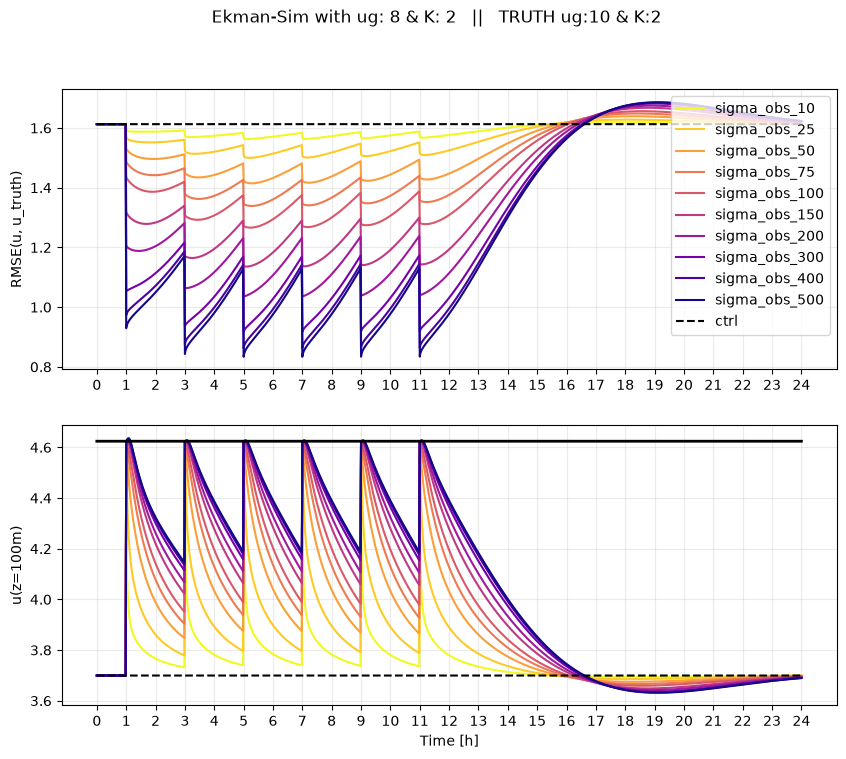

In [133]:
UG_SIM = 8
K_SIM = 2 #K_TRUE
H_OBS = 100
SIGMA_OBS = 50

VAR = "u"

assim_dict = dict()
for idx, loc in enumerate([10,25,50,75,100,150,200,300,400,500]):
    runc = True if idx==0 else False
    
    output = assim_wind_seq(
        UG_SIM, K_SIM, 
        h_obs = H_OBS, 
        sigma_obs = loc,
        run_ctrl = runc
        )
    if runc:
        ds_ctrl = output[1]
    
    assim_dict[f"sigma_obs_{loc}"] = output[0] if runc else output



# ---- PLOTTING
fig, ax = plt.subplots(nrows=2, figsize=(10, 8))

H_PLOT = 100

# Colors from inferno colormap
cmap = plt.get_cmap("plasma_r")
colors = cmap(np.linspace(0, 0.99, len(assim_dict)))
for (label, ds_sim), color in zip(assim_dict.items(), colors):

    z = slice(None, None)
    rmse_da = rmse(ds_sim[VAR].sel(z=z), ds_true[VAR].sel(z=z), dim="z")
    rmse_ctrl = rmse(ds_ctrl[VAR].sel(z=z), ds_true[VAR].sel(z=z), dim="z")

    ds_sim[VAR].sel(z=H_PLOT).plot(ax=ax[1], color=color, label=label)
    rmse_da.plot(ax=ax[0], color=color, label=label)

rmse_ctrl.plot(ax=ax[0], c="k", linestyle="--", label="ctrl")

ds_true[VAR].sel(z=H_PLOT).plot(ax=ax[1], label="truth", c="k", linewidth=2)
ds_ctrl[VAR].sel(z=H_PLOT).plot(ax=ax[1], label="ctrl", c="k", linestyle="--")


ax[0].set_ylabel(f"RMSE({VAR}, {VAR}_truth)")
ax[1].set_ylabel(f"{VAR}(z={H_PLOT}m)")

xticks = ds_sim.time.values[::60]
xlabels = [f'{int(x//3600)}' for x in xticks]

for i in range(2):
    ax[i].set_xticks(xticks, labels=xlabels)
    ax[i].set_xlabel("")
    ax[i].grid(alpha=.25)
    ax[i].set_title("")
ax[1].set_xlabel("Time [h]")
ax[0].legend(loc="upper right")

fig.suptitle(f"Ekman-Sim with ug: {UG_SIM} & K: {K_SIM}   ||   TRUTH ug:{UG_TRUE} & K:{K_TRUE}")


In [143]:
fig, ax = plt.subplots(figsize=(7, 7))
items = list(assim_dict.items())
colors = plt.get_cmap("plasma_r")(np.linspace(0, 0.99, len(items)))

lines = [ax.plot([], [], color=c, lw=1.5, alpha=0.8, label=label)[0]
         for (label, _), c in zip(items, colors)]

truth, = ax.plot([], [], 'k-', lw=3, label='truth', zorder=10)
ctrl,  = ax.plot([], [], 'k--', lw=2.5, label='ctrl', zorder=10)

ax.set(xlabel="u [m/s]", ylabel="z [m]",
       xlim=(min(float(ds.u.min()) for _, ds in items + [('truth', ds_true), ('ctrl', ds_ctrl)]),
             max(float(ds.u.max()) for _, ds in items + [('truth', ds_true), ('ctrl', ds_ctrl)])),
       ylim=(float(ds_true.z.min()), float(ds_true.z.max())))
ax.grid(alpha=0.25)
ax.legend(bbox_to_anchor=(.02, 1), loc="upper left")

def update(i):
    for line, (_, ds) in zip(lines, items):
        line.set_data(ds.u.isel(time=i), ds.z)
    truth.set_data(ds_true.u.isel(time=i), ds_true.z)
    ctrl.set_data(ds_ctrl.u.isel(time=i), ds_ctrl.z)
    ax.set_title(f"Time = {ds_true.time.values[i]/3600:.1f} h")
    return lines + [truth, ctrl]

step = 30 #max(1, ds_true.sizes["time"] // 30)
ani = FuncAnimation(fig, update, frames=range(0, ds_true.sizes["time"], step),
                    interval=100)

plt.close(fig)
fig.suptitle(f"Ekman-Sim with ug: {UG_SIM} & K: {K_SIM}   ||   TRUTH ug:{UG_TRUE} & K:{K_TRUE}")
HTML(ani.to_jshtml())

In [142]:
step = max(1, ds_true.sizes["time"] // 30)
step

48

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7), sharex=True, sharey=True)
items = list(assim_dict.items())
lines = []

for ax, (label, ds) in zip(axes.flat, items):
    line, = ax.plot([], [], lw=2)
    lines.append(line)
    ax.set_title(label)
    ax.grid(alpha=0.25)

axes[0, 0].set_xlim(
    min(float(ds.u.min()) for _, ds in items),
    max(float(ds.u.max()) for _, ds in items)
)
axes[0, 0].set_ylim(float(ds.z.min()), float(ds.z.max()))
fig.supxlabel("u [m/s]")
fig.supylabel("z [m]")

def update(i):
    for line, (_, ds) in zip(lines, items):
        line.set_data(ds.u.isel(time=i), ds.z)
    fig.suptitle(f"Time = {ds.time.values[i]/3600:.1f} h")
    return lines

step = max(1, ds.sizes["time"] // 100)
ani = FuncAnimation(fig, update, frames=range(0, ds.sizes["time"], step), interval=100)

plt.close(fig)
HTML(ani.to_jshtml())

Text(0.5, 1.0, '')

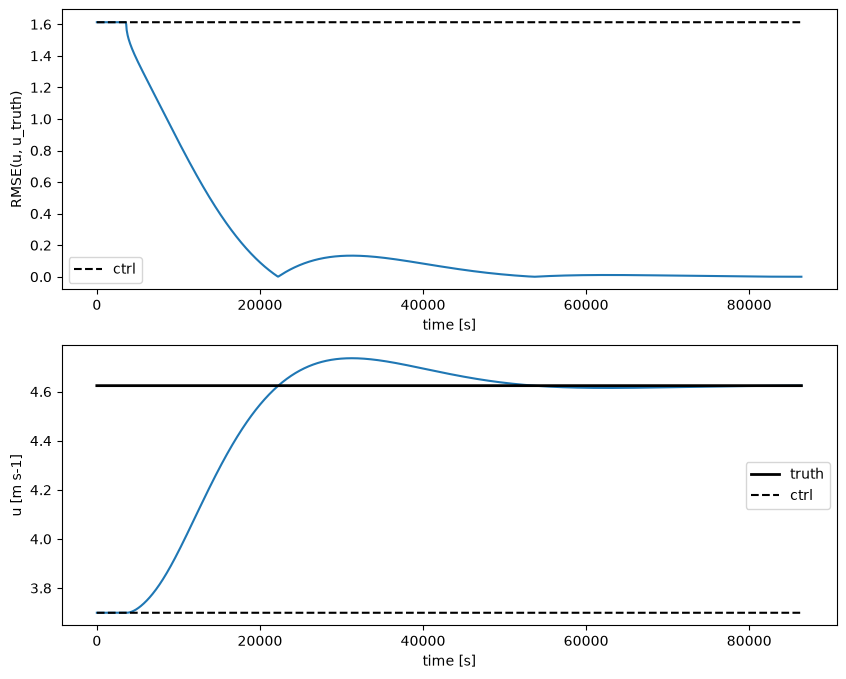

In [ ]:
############################
# --- Modify Geo-Wind
############################


UG_SIM = 8
K_SIM = K_TRUE

model = Ekman(ug=UG_SIM, vg=0, K=K_SIM, config=config)
model.spin_up()

sim = Simulation(model)

# ---- Run DA-experiment
analysis = sim.copy()
# analysis_ds = analysis.run(until=3600)

control = sim.copy()
ds_ctrl = control.run(until=TTOT)


# Schedule assimilation
t_update = 1 * 3600
analysis.schedule(t_update,StateUpdater(ug=UG_TRUE))

# ---- Run simulation
ds_analysis = analysis.run(until=TTOT)


# ---- Calc RMSE
z = slice(None, None)
rmse_da = rmse(ds_analysis["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")
rmse_ctrl = rmse(ds_ctrl["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")


# ---- Plotting
H_PLOT = 100
fig, ax = plt.subplots(nrows=2, figsize=(10, 8))

rmse_da.plot(ax=ax[0])
rmse_ctrl.plot(ax=ax[0], c="k", linestyle="--", label="ctrl")

ds_analysis.u.sel(z=H_PLOT).plot(ax=ax[1])
ds_true.u.sel(z=H_PLOT).plot(ax=ax[1], label="truth", c="k", linewidth=2)
ds_ctrl.u.sel(z=H_PLOT).plot(ax=ax[1], label="ctrl", c="k", linestyle="--")

ax[0].legend()
ax[1].legend()

ax[0].set_title("")
ax[0].set_ylabel("RMSE(u, u_truth)")
ax[1].set_title("")

Text(0.5, 1.0, '')

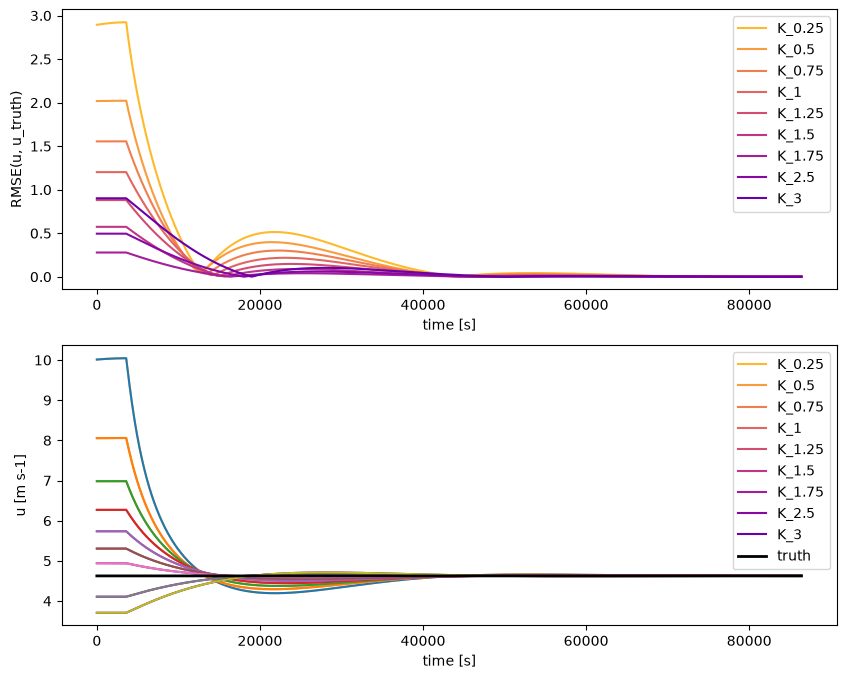

In [ ]:
UG_SIM = UG_TRUE
K_SIM = 1.5



assim_dict_K = dict()
for idx, k_sim in enumerate([0.25, 0.5, 0.75, 1, 1.25, 1.5, 1.75, 2.5, 3]):

    model = Ekman(ug=UG_SIM, vg=0, K=k_sim, config=config)
    model.spin_up()

    sim = Simulation(model)

    # ---- Run DA-experiment
    analysis = sim.copy()
    # analysis_ds = analysis.run(until=3600)


    # Schedule assimilation
    t_update = 1 * 3600
    analysis.schedule(t_update,StateUpdater(ug=UG_TRUE, K=K_TRUE))

    # ---- Run simulation
    ds_analysis = analysis.run(until=TTOT)

    assim_dict_K[f"K_{k_sim}"] = ds_analysis



# ---- PLOTTING
fig, ax = plt.subplots(nrows=2, figsize=(10, 8))

H_PLOT = 100

# Colors from inferno colormap
cmap = plt.get_cmap("plasma_r")
colors = cmap(np.linspace(0.15, 0.8, len(assim_dict_K)))

for (label, ds_sim), color in zip(assim_dict_K.items(), colors):
    z = slice(None, None)
    rmse_da = rmse(ds_sim["u"].sel(z=z), ds_true["u"].sel(z=z), dim="z")

    ds_sim.u.sel(z=H_PLOT).plot(ax=ax[1], color=color, label=label)
    rmse_da.plot(ax=ax[0], color=color, label=label)

    ds_sim.u.sel(z=H_PLOT).plot(ax=ax[1])


ds_true.u.sel(z=H_PLOT).plot(ax=ax[1], label="truth", c="k", linewidth=2)

ax[0].legend()
ax[1].legend()

ax[0].set_title("")
ax[0].set_ylabel("RMSE(u, u_truth)")
ax[1].set_title("")

In [144]:
# ====================
# --- TRUTH RUN
# ====================
config = EkmanConfig(  
    spinup_seconds = 60 * 3600,
    output_interval = 60,
    )



model_true = Ekman(ug=UG_TRUE, vg=0, K=K_TRUE, config=config)
model_true.spin_up()

sim_true = Simulation(model_true)

# --- Run Control
truth_run = sim_true.copy()     # Independent branches
ds_true = truth_run.run(until=TTOT) # Control Forecast


In [149]:
truth_run.model.state.u

array([ 0.        ,  0.24765346,  0.49499696,  0.74173578,  0.98759006,
        1.23229439,  1.47559745,  1.71726162,  1.95706259,  2.19478902,
        2.43024211,  2.66323525,  2.89359369,  3.12115411,  3.34576431,
        3.56728284,  3.78557865,  4.00053072,  4.21202777,  4.41996787,
        4.62425814,  4.82481443,  5.02156098,  5.21443011,  5.40336193,
        5.58830403,  5.76921117,  5.94604501,  6.11877381,  6.28737219,
        6.45182081,  6.61210615,  6.7682202 ,  6.92016029,  7.06792877,
        7.2115328 ,  7.35098414,  7.4862989 ,  7.61749732,  7.74460357,
        7.86764556,  7.98665469,  8.10166574,  8.21271658,  8.3198481 ,
        8.42310394,  8.52253039,  8.61817619,  8.7100924 ,  8.79833224,
        8.88295093,  8.96400558,  9.04155504,  9.11565978,  9.18638177,
        9.25378437,  9.31793219,  9.37889103,  9.43672773,  9.49151012,
        9.5433069 ,  9.59218758,  9.63822236,  9.6814821 ,  9.7220382 ,
        9.75996259,  9.7953276 ,  9.82820596,  9.85867072,  9.88

In [ ]:
idx = np.argmin(abs(truth_run.model.z - H_OBS))
idx

obsop = LinearObservationOperator(
    obs_states=[0,1],
    obs_indices=[idx],
    state_dim=truth_run.model.state.u.shape[0],
    num_states=2    
    )

In [159]:
obsop.obs_matrix

BCOO(float32[2, 202], nse=2)

In [173]:
state = np.asarray([truth_run.model.state.u,truth_run.model.state.v])
state.shape

(2, 101)

In [174]:
obsop._obs_operator(state)

Array([4.624258, 2.987187], dtype=float32)